# Gini-Index bei festem β: Sparsity des Varix-Codes über Training und β

**Frage.** Wie dünn besetzt wird der Varix-Code, wenn β von Anfang an fest ist, und wie hängt das mit β, Rate,
Trustworthiness und Downstream-AUC zusammen? `sparsity_ladder` hat auf der Leiter gezeigt: Der Null-Anteil steigt von
2–17 % (Ende Warm-up) auf 83–84 % an der Kante. Dort wechselt β aber alle 100 Epochen; hier ist β über das ganze Training fest.

**Daten: die 106er-Studie** `large_scale_results/fixed_beta_106_epochs750_2026_10_27` (kein neues Training).
Pipeline `new_beta_varix_experiments.py`, `anneal_function = "no-annealing"`, 750 Epochen, `split_seed = 2`,
Lernrate 5·10⁻⁴, `weight_decay` 0,01, Snapshots (μ, logvar, z für Train, Validierung, Test) alle 50 Epochen.

- **TCGA, d = 8:** 15 Stufen β/d von 0 bis 1,5·10⁻², Seeds 13, 17, 23, 31 (60 Läufe), dazu 2 Läufe β = 0 ohne
  Weight Decay (hier nicht verwendet).
- **Circle und Swiss Roll, d = 2:** je 11 Stufen β/d, Seeds 13 und 17. Negativkontrollen: keine Cluster, Mannigfaltigkeit.

**Gemessen pro Snapshot** (Validierung): Sparsity und Gini auf μ (Mechanismus), Rate aus μ und logvar,
Trustworthiness T(k = 20) auf z gegen die vorverarbeiteten Eingaben X, Downstream-AUC auf z mit dem Pipeline-Evaluator.
Die Klemme setzt μ < 10⁻⁷ auf exakt 0 (`_varix_architecture.py`).

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LogNorm
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import trustworthiness

PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "beta_vae_experiments").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from beta_vae_experiments.metrics.evaluation.downstream import ClassAUCEvaluator, snapshot_tasks

STUDY = PROJECT_ROOT / "beta_vae_experiments" / "large_scale_results" / "fixed_beta_106_epochs750_2026_10_27"
OUTPUT = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "gini_index"
OUTPUT.mkdir(parents=True, exist_ok=True)
LADDER_SPARSITY = PROJECT_ROOT / "beta_vae_experiments" / "outputs" / "sparsity_ladder" / "sparsity_levels.csv"

EPOCHS, SNAPSHOT_EVERY, WEIGHT_DECAY = 750, 50, 0.01
SNAPSHOT_EPOCHS = tuple(range(SNAPSHOT_EVERY, EPOCHS + 1, SNAPSHOT_EVERY))
DEAD = 0.99            # Dimension tot, wenn ≥ 99 % der Patienten auf der Klemme sitzen
TASKS = {"cancer_type": "auc_cancer", "sex_mixed_cancers": "auc_sex_mixed"}
PREPROCESSED = {"tcga": "tcga_split2", "circle": "circle_split2", "swiss_roll": "swiss_roll_split2"}

run_rows = []
for tag_folder in sorted((STUDY / "runs").iterdir()):
    match = re.fullmatch(r"(tcga|circle|swiss_roll)_b([^_]+)_s(\d+)_wd([\d.]+)", tag_folder.name)
    if not match:
        continue
    folders = [path for path in (tag_folder / "run_analysis").iterdir() if path.is_dir()]
    assert len(folders) == 1, tag_folder
    run_rows.append(dict(tag=tag_folder.name, dataset=match[1], beta_over_d=float(match[2]), seed=int(match[3]),
                         weight_decay=float(match[4]), folder=folders[0],
                         latent_dim=int(re.search(r"latent_dim-(\d+)", folders[0].name)[1])))
runs = pd.DataFrame(run_rows)
runs = runs[runs.weight_decay.eq(WEIGHT_DECAY)].reset_index(drop=True)
runs["done"] = [(folder / "epoch_snapshots" / f"epoch_{EPOCHS:05d}_valid.npz").exists() for folder in runs.folder]
assert runs.done.all(), runs[~runs.done].tag.tolist()
display(runs.groupby("dataset").agg(runs=("tag", "size"), betas=("beta_over_d", "nunique"),
                                    seeds=("seed", lambda s: sorted(s.unique())), latent_dim=("latent_dim", "first")))
TCGA_BETAS = tuple(sorted(runs[runs.dataset.eq("tcga")].beta_over_d.unique()))
TCGA_SEEDS = tuple(sorted(runs[runs.dataset.eq("tcga")].seed.unique()))
BETA_NORM = LogNorm(vmin=min(b for b in TCGA_BETAS if b > 0), vmax=max(TCGA_BETAS))


def beta_color(beta):
    return "black" if beta == 0 else plt.cm.viridis(BETA_NORM(beta))

,runs,betas,seeds,latent_dim
dataset,,,,
circle,22,11,"[13, 17]",2
swiss_roll,22,11,"[13, 17]",2
tcga,60,15,"[13, 17, 23, 31]",8


## 1. Eingeschwungen nach 750 Epochen?

Relative Änderung des Medians über 50 Epochen zwischen Epoche 650 und 750 (Validierung), für Rekonstruktion und KL.
Schwelle wie bei den Referenzmodellen in `tomato_ladder`: |Änderung| ≤ 1 %.

In [2]:
convergence_rows = []
for _, run in runs[runs.dataset.eq("tcga")].iterrows():
    losses = pd.read_csv(run.folder / "epoch_losses.csv").query("split == 'valid'").set_index("epoch")

    def change(series, end=EPOCHS, start=EPOCHS - 100):
        before = series.loc[start - 50:start].median()
        return float(series.loc[end - 50:end].median() / before - 1) if before else np.nan

    convergence_rows.append(dict(beta_over_d=run.beta_over_d, seed=run.seed, recon=change(losses.recon_loss),
                                 kl=change(losses.var_loss)))
convergence = pd.DataFrame(convergence_rows)
display(convergence.pivot_table(index="beta_over_d", columns="seed", values=["recon", "kl"]).style.format("{:+.3f}")
        .map(lambda value: "color: #c0392b" if abs(value) > 0.01 else "")
        .set_caption("relative Änderung Epoche 650 → 750 (rot: > 1 %); KL bei β = 0 nicht definiert"))

## 2. Kennzahlen pro Snapshot

Gini nach Hurley & Rickard (2009): skaleninvariant, 0 bei Gleichheit, 1 − 1/n bei einem einzigen Eintrag, = p bei einem
Anteil p Nullen (Test unten und in `sparsity_ladder` Abschnitt 1).

- **pro Dimension:** Null-Anteil p₀, Gini über Patienten, Rate R_j = mean_i KL_ij
- **pro Patient:** Gini über die Dimensionen (Median, Quartile), aktive Dimensionen
- **Gini der ganzen μ-Matrix** (alle Patienten × Dimensionen als ein Vektor): Hauptmaß, weil er auch mit toten
  Dimensionen definiert ist. Der Median des Gini pro Dimension über die *lebenden* Dimensionen ist an der Kante verzerrt:
  dort sterben die dünnsten Dimensionen, die dichteren bleiben übrig, und der Median sinkt (Überlebenden-Effekt).
- **gesamt:** Null-Anteil, tote Dimensionen, Patienten ganz auf der Klemme, Null-Muster, Gini der Rate,
  D_eff = (Σ R_j)² / Σ R_j²
- **Preservation:** T(k = 20) auf dem gespeicherten z gegen X (sklearn)
- **Downstream** (nur TCGA): logistische Regression auf z, Train → Validierung, AUC One-vs-One, mit
  `snapshot_tasks` und `ClassAUCEvaluator` wie in der Pipeline (`evaluate_epoch_downstream`); Aufgaben Krebsart und
  Geschlecht in gemischten Krebsarten (`sex_mixed_cancers`).

In [3]:
def gini(matrix):
    """Gini jeder Zeile (Hurley & Rickard 2009); Zeilen nur aus Nullen → NaN."""
    values = np.sort(np.abs(np.atleast_2d(np.asarray(matrix, dtype=np.float64))), axis=1)
    n = values.shape[1]
    total = values.sum(axis=1, keepdims=True)
    k = np.arange(1, n + 1)
    result = 1 - 2 * ((values / np.where(total == 0, 1, total)) * (n - k + 0.5) / n).sum(axis=1)
    return np.where(total[:, 0] == 0, np.nan, result)


example = np.random.default_rng(0).exponential(size=(3, 800))
assert np.allclose(gini(example), gini(0.01 * example))
assert np.isclose(gini(np.r_[np.zeros(600), np.ones(200)])[0], 0.75) and np.isclose(gini(np.eye(8)[0])[0], 7 / 8)
assert np.isnan(gini(np.zeros(8))[0])


def load_split(folder, epoch, split):
    with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_{split}.npz") as saved:
        order = np.argsort(saved["sample_ids"].astype(str))
        return {key: saved[key][order] for key in ("sample_ids", "mu", "logvar", "z")}


inputs = {}
for dataset, name in PREPROCESSED.items():
    with np.load(STUDY / "preprocessed_data" / name / "input_valid.npz") as saved:
        order = np.argsort(saved["sample_ids"].astype(str))
        inputs[dataset] = (saved["sample_ids"].astype(str)[order], saved["x"][order].astype(np.float64))


def snapshot_measures(mu, logvar):
    assert mu.min() >= 0 and not ((mu > 0) & (mu < 1e-7)).any(), "Klemme anders als erwartet"
    zero = mu == 0
    rate = (0.5 * (mu ** 2 + np.exp(logvar) - 1 - logvar)).mean(0)
    dims = pd.DataFrame(dict(dim=np.arange(mu.shape[1]), rate=rate, zero_share=zero.mean(0), gini=gini(mu.T)))
    patient_gini = gini(mu)
    has_patient_gini = np.isfinite(patient_gini).any()
    live = dims[dims.zero_share.lt(DEAD)]
    summary = dict(rate=rate.sum(), zero_share=zero.mean(), dead_dims=int((zero.mean(0) >= DEAD).sum()),
                   gini_dim_median=live.gini.median(),
                   gini_patient_median=np.nanmedian(patient_gini) if has_patient_gini else np.nan,
                   gini_patient_q25=np.nanquantile(patient_gini, .25) if has_patient_gini else np.nan,
                   gini_patient_q75=np.nanquantile(patient_gini, .75) if has_patient_gini else np.nan,
                   active_dims_per_patient=(~zero).sum(1).mean(), patients_all_zero=zero.all(1).mean(),
                   patterns=len(np.unique(~zero, axis=0)), gini_rate=gini(rate)[0],
                   d_eff=rate.sum() ** 2 / (rate ** 2).sum() if rate.sum() > 0 else np.nan)
    return dims, summary


def downstream(folder, train, valid):
    """AUC auf z wie `evaluate_epoch_downstream`, nur für die Aufgaben in TASKS."""
    labels, features = {}, {}
    for split, arrays in (("train", train), ("valid", valid)):
        table = pd.read_parquet(folder / "epoch_snapshots" / f"labels_{split}.parquet")
        table.index = table.index.astype(str)
        labels[split] = table.loc[arrays["sample_ids"].astype(str)]
        features[split] = pd.DataFrame(arrays["z"], index=labels[split].index)
    scores = {}
    for task in snapshot_tasks(labels):
        if task["name"] not in TASKS:
            continue
        frames, annotations, partitions = [], [], []
        for split in ("train", "valid"):
            keep = task["keep"][split]
            frame = features[split].loc[keep]
            frames.append(frame)
            annotations.append(task["y"][split].loc[keep].rename(task["target"]))
            partitions.append(pd.DataFrame(dict(SAMPLE_ID=frame.index, SPLIT=split)))
        result = ClassAUCEvaluator()._single_ml_presplit(
            pd.concat(partitions, ignore_index=True), pd.concat(frames), pd.concat(annotations).to_frame(),
            task["target"], LogisticRegression(max_iter=1000), "roc_auc_ovo", "classification", top_k_classes=None)
        scores[TASKS[task["name"]]] = float(result.loc[result.score_split.eq("valid"), "value"].iloc[0])
    return scores


dims_cache, summary_cache = OUTPUT / "gini_dims.parquet", OUTPUT / "gini_summary.parquet"
dims = pd.read_parquet(dims_cache) if dims_cache.exists() else pd.DataFrame(columns=["tag"])
summary = pd.read_parquet(summary_cache) if summary_cache.exists() else pd.DataFrame(columns=["tag"])
for _, run in runs.iterrows():
    if run.tag in set(summary.tag):
        continue
    new_dims, new_summary = [], []
    x_ids, x_valid = inputs[run.dataset]
    for epoch in SNAPSHOT_EPOCHS:
        valid = load_split(run.folder, epoch, "valid")
        assert np.array_equal(valid["sample_ids"].astype(str), x_ids), "Validierungs-IDs passen nicht zu X"
        part, row = snapshot_measures(valid["mu"].astype(np.float64), valid["logvar"].astype(np.float64))
        row["trustworthiness_z"] = float(trustworthiness(x_valid, valid["z"].astype(np.float64), n_neighbors=20))
        if run.dataset == "tcga":
            row |= downstream(run.folder, load_split(run.folder, epoch, "train"), valid)
        info = dict(tag=run.tag, dataset=run.dataset, seed=run.seed, beta_over_d=run.beta_over_d, epoch=epoch)
        new_dims.append(part.assign(**info))
        new_summary.append(info | row)
    dims = pd.concat([dims, *new_dims], ignore_index=True)
    summary = pd.concat([summary, pd.DataFrame(new_summary)], ignore_index=True)
    dims.to_parquet(dims_cache)
    summary.to_parquet(summary_cache)
dims = dims.astype({"seed": int, "epoch": int, "dim": int})
summary = summary.astype({"seed": int, "epoch": int})

# Gini über die ganze μ-Matrix: definiert, solange nicht alles 0 ist, ohne Konvention für tote Dimensionen
pooled_cache = OUTPUT / "gini_pooled.parquet"
pooled = pd.read_parquet(pooled_cache) if pooled_cache.exists() else pd.DataFrame(columns=["tag", "epoch", "gini_pooled"])
missing = runs[~runs.tag.isin(set(pooled.tag))]
if len(missing):
    pooled_rows = [dict(tag=run.tag, epoch=epoch, gini_pooled=gini(load_split(run.folder, epoch, "valid")["mu"].ravel())[0])
                   for _, run in missing.iterrows() for epoch in SNAPSHOT_EPOCHS]
    pooled = pd.concat([pooled, pd.DataFrame(pooled_rows)], ignore_index=True)
    pooled.to_parquet(pooled_cache)
summary = summary.drop(columns="gini_pooled", errors="ignore").merge(pooled.astype({"epoch": int}), on=["tag", "epoch"], how="left")
tcga = summary[summary.dataset.eq("tcga")]
print(f"{summary.tag.nunique()} Läufe, {len(summary)} Snapshots ausgewertet")

104 Läufe, 1560 Snapshots ausgewertet


## 3. Sparsity über die Epochen (TCGA)

Pro Seed eine Spalte, Farbe = β/d (schwarz: β = 0, sonst viridis, logarithmisch).

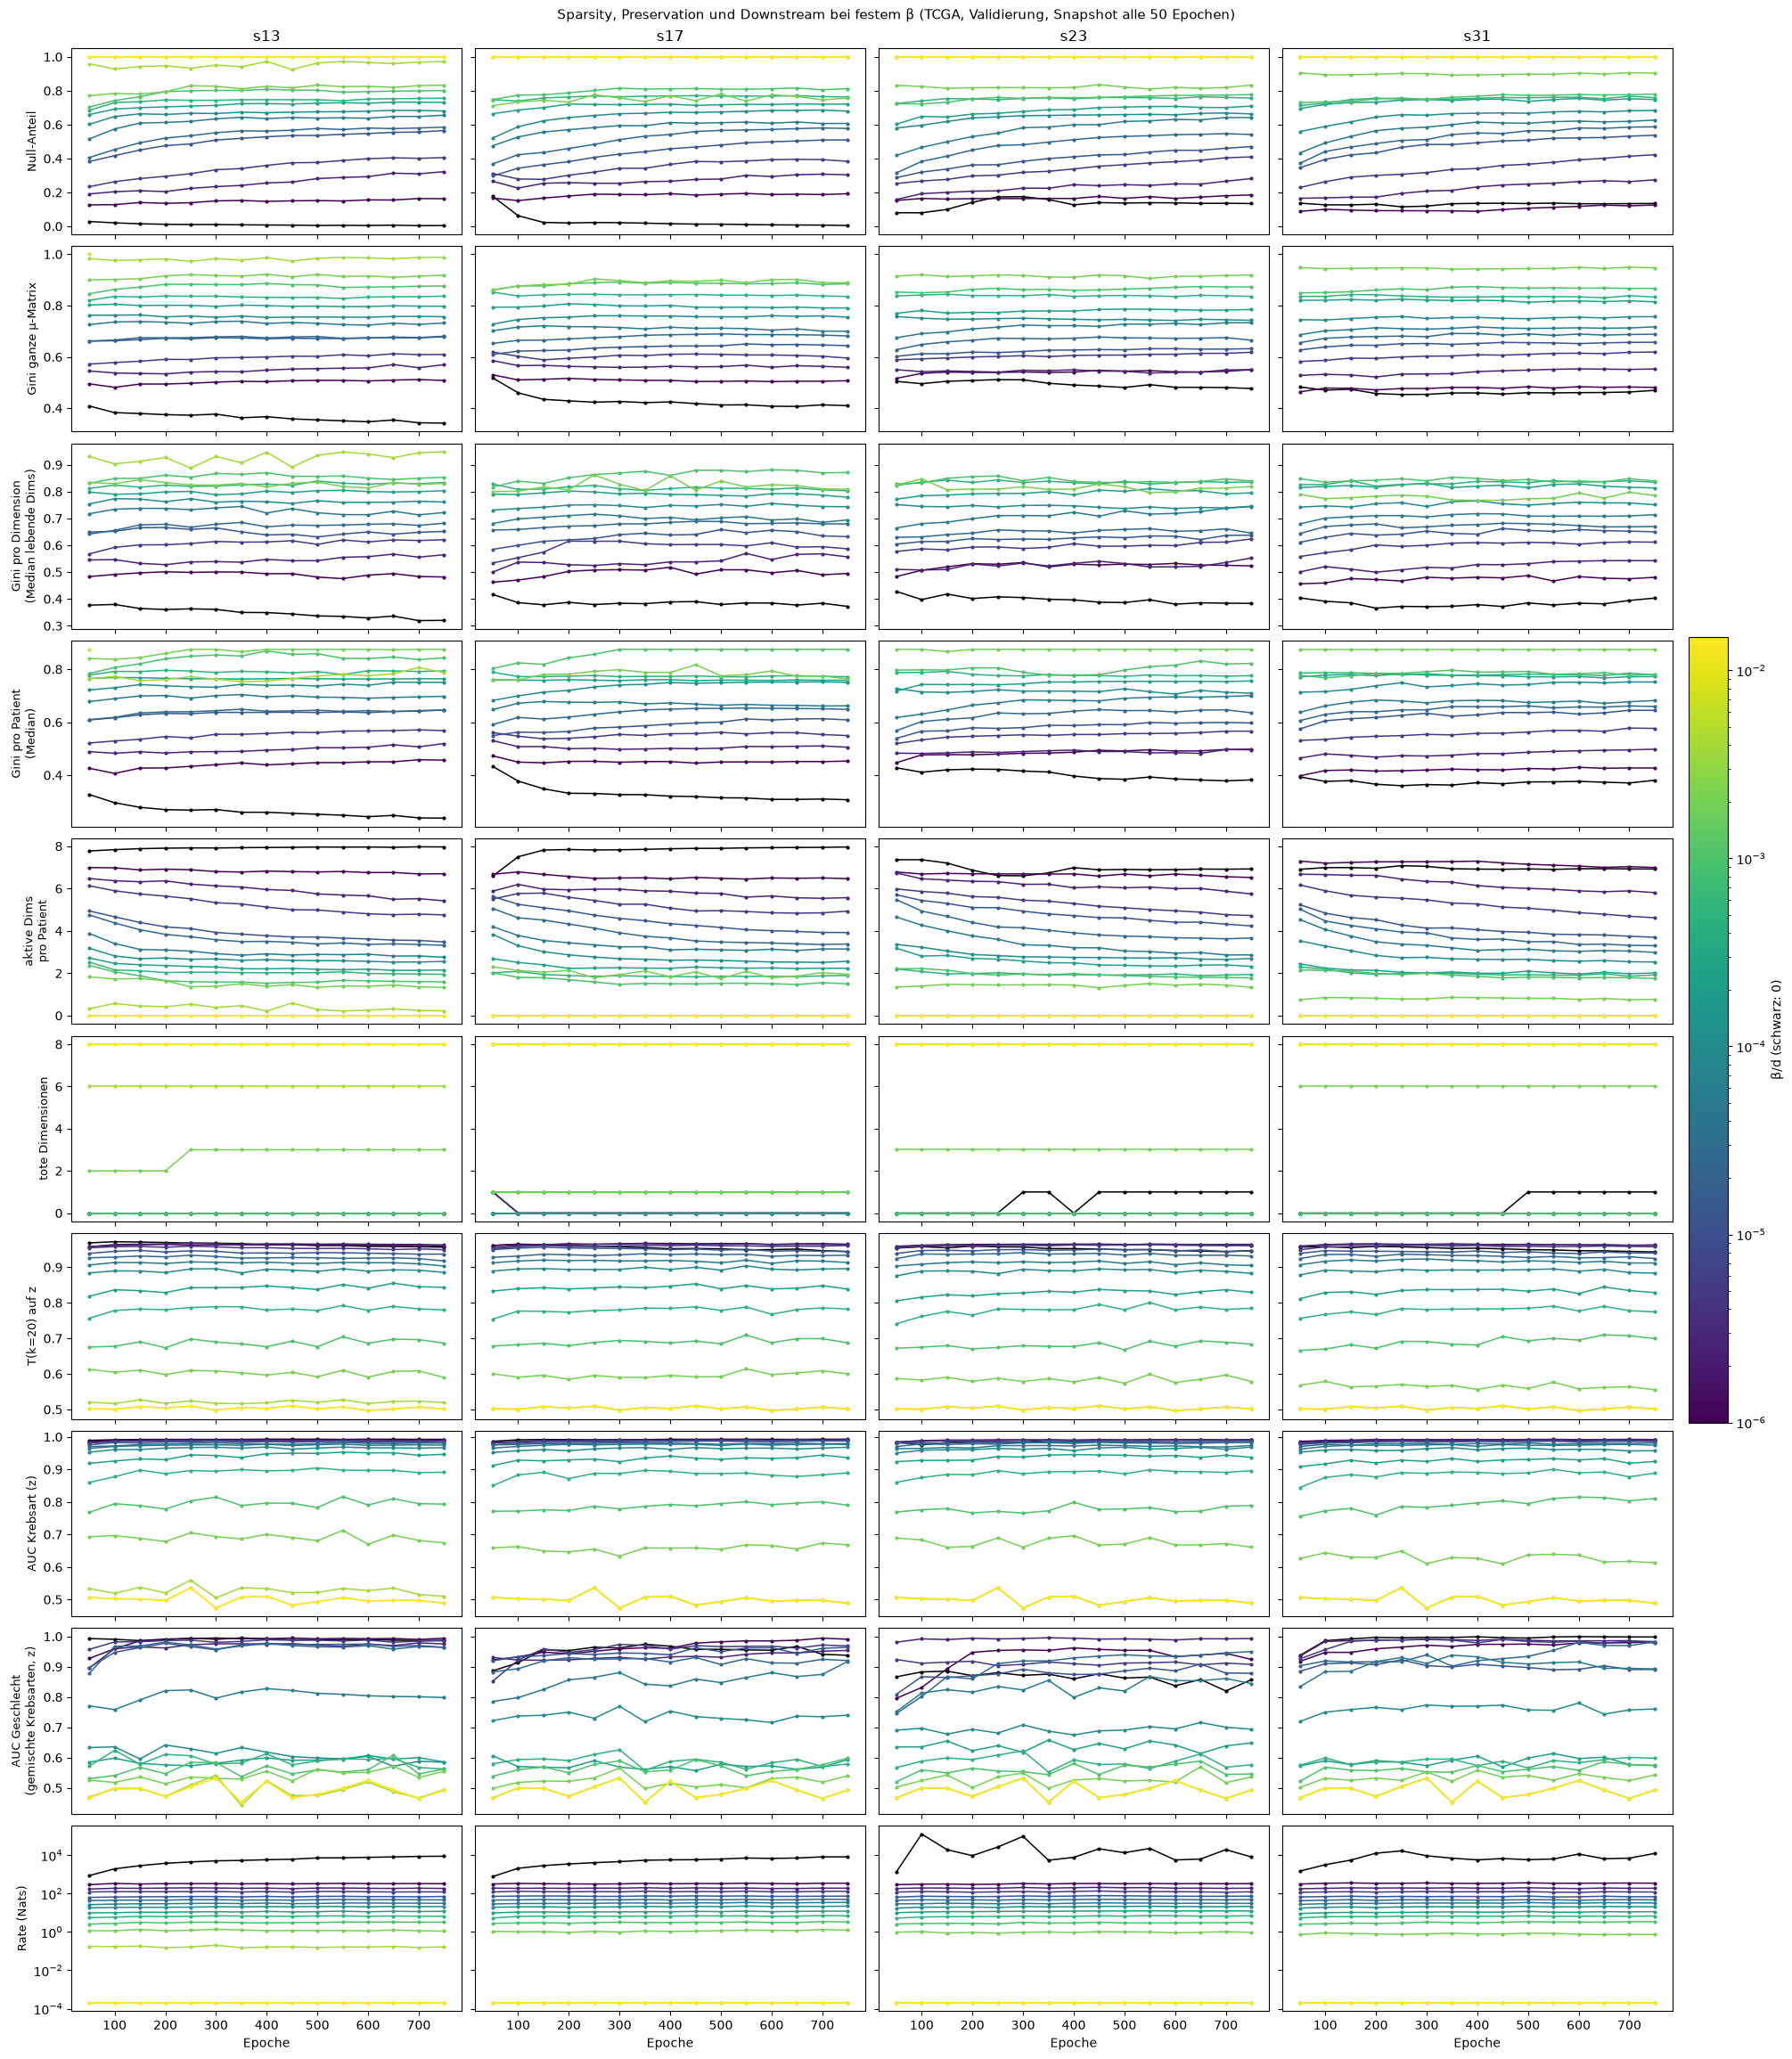

In [4]:
rows = [("zero_share", "Null-Anteil"), ("gini_pooled", "Gini ganze μ-Matrix"), ("gini_dim_median", "Gini pro Dimension\n(Median lebende Dims)"),
        ("gini_patient_median", "Gini pro Patient\n(Median)"), ("active_dims_per_patient", "aktive Dims\npro Patient"),
        ("dead_dims", "tote Dimensionen"), ("trustworthiness_z", "T(k=20) auf z"),
        ("auc_cancer", "AUC Krebsart (z)"), ("auc_sex_mixed", "AUC Geschlecht\n(gemischte Krebsarten, z)"),
        ("rate", "Rate (Nats)")]
fig, axes = plt.subplots(len(rows), len(TCGA_SEEDS), figsize=(5 * len(TCGA_SEEDS), 2.3 * len(rows)), sharex=True, sharey="row",
                         layout="constrained")
for column, seed in enumerate(TCGA_SEEDS):
    for beta, part in tcga[tcga.seed.eq(seed)].groupby("beta_over_d"):
        part = part.sort_values("epoch")
        for row, (key, _) in enumerate(rows):
            axes[row, column].plot(part.epoch, part[key], "o-", ms=2, lw=1.1, color=beta_color(beta))
    axes[0, column].set_title(f"s{seed}")
    axes[-1, column].set_xlabel("Epoche")
for ax, (_, label) in zip(axes[:, 0], rows):
    ax.set_ylabel(label, fontsize=9)
axes[-1, 0].set_yscale("log")
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=BETA_NORM, cmap="viridis"), ax=axes, location="right", shrink=.4, pad=.01)
colorbar.set_label("β/d (schwarz: 0)")
fig.suptitle("Sparsity, Preservation und Downstream bei festem β (TCGA, Validierung, Snapshot alle 50 Epochen)", fontsize=11)
fig.savefig(OUTPUT / "gini_epochs.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Endzustand über β (Epoche 750)

x = β/d (symlog, β = 0 links), Punkte = Seeds, Linie = Median. Die gestrichelte Linie markiert β/d = 2·10⁻³, die letzte
Stufe vor dem Collapse auf der Leiter. Unten rechts: Gini pro Patient gegen AUC Krebsart über alle Läufe.

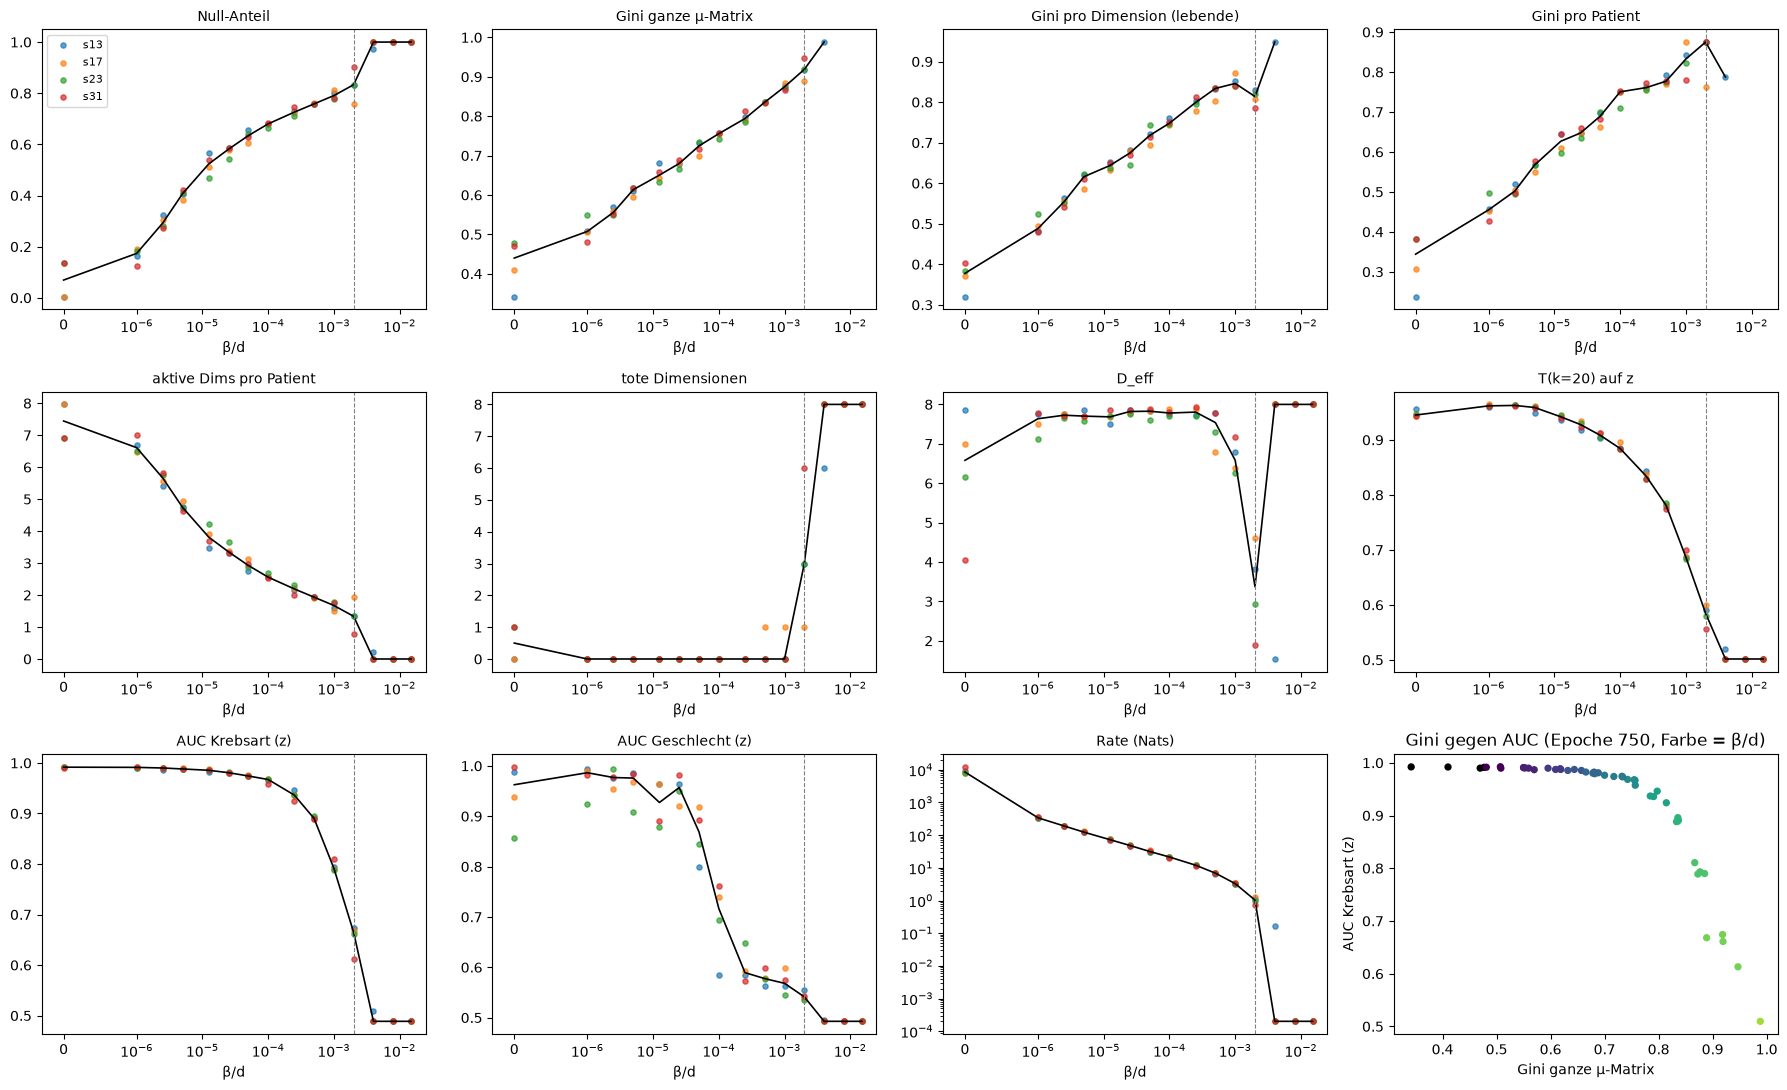

In [5]:
final = tcga[tcga.epoch.eq(EPOCHS)]
panels = [("zero_share", "Null-Anteil"), ("gini_pooled", "Gini ganze μ-Matrix"), ("gini_dim_median", "Gini pro Dimension (lebende)"), ("gini_patient_median", "Gini pro Patient"),
          ("active_dims_per_patient", "aktive Dims pro Patient"), ("dead_dims", "tote Dimensionen"), ("d_eff", "D_eff"),
          ("trustworthiness_z", "T(k=20) auf z"), ("auc_cancer", "AUC Krebsart (z)"), ("auc_sex_mixed", "AUC Geschlecht (z)"),
          ("rate", "Rate (Nats)")]
fig, axes = plt.subplots(3, 4, figsize=(18, 11))
assert len(panels) + 1 <= axes.size
for ax, (key, label) in zip(axes.flat, panels):
    for seed, part in final.groupby("seed"):
        ax.scatter(part.beta_over_d, part[key], s=14, alpha=.7, label=f"s{seed}")
    median = final.groupby("beta_over_d")[key].median()
    ax.plot(median.index, median.values, color="k", lw=1.2)
    ax.axvline(2e-3, color="grey", ls="--", lw=.8)
    ax.set_xscale("symlog", linthresh=1e-6)
    ax.set_xlim(-3e-7, 2.5e-2)
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("β/d")
axes.flat[len(panels) - 1].set_yscale("log")
axes.flat[0].legend(fontsize=8)
ax = axes.flat[len(panels)]
ax.scatter(final.gini_pooled, final.auc_cancer, s=18, c=[beta_color(beta) for beta in final.beta_over_d])
ax.set(xlabel="Gini ganze μ-Matrix", ylabel="AUC Krebsart (z)", title="Gini gegen AUC (Epoche 750, Farbe = β/d)")
fig.tight_layout()
fig.savefig(OUTPUT / "gini_vs_beta.png", dpi=160)
plt.show()

## 5. Gini pro Dimension über die Epochen

Jede Linie eine Dimension; Zeilen = ausgewählte β/d, Spalten = Seeds. Bricht eine Linie ab, sitzen alle Patienten dieser
Dimension auf der Klemme (Gini undefiniert).

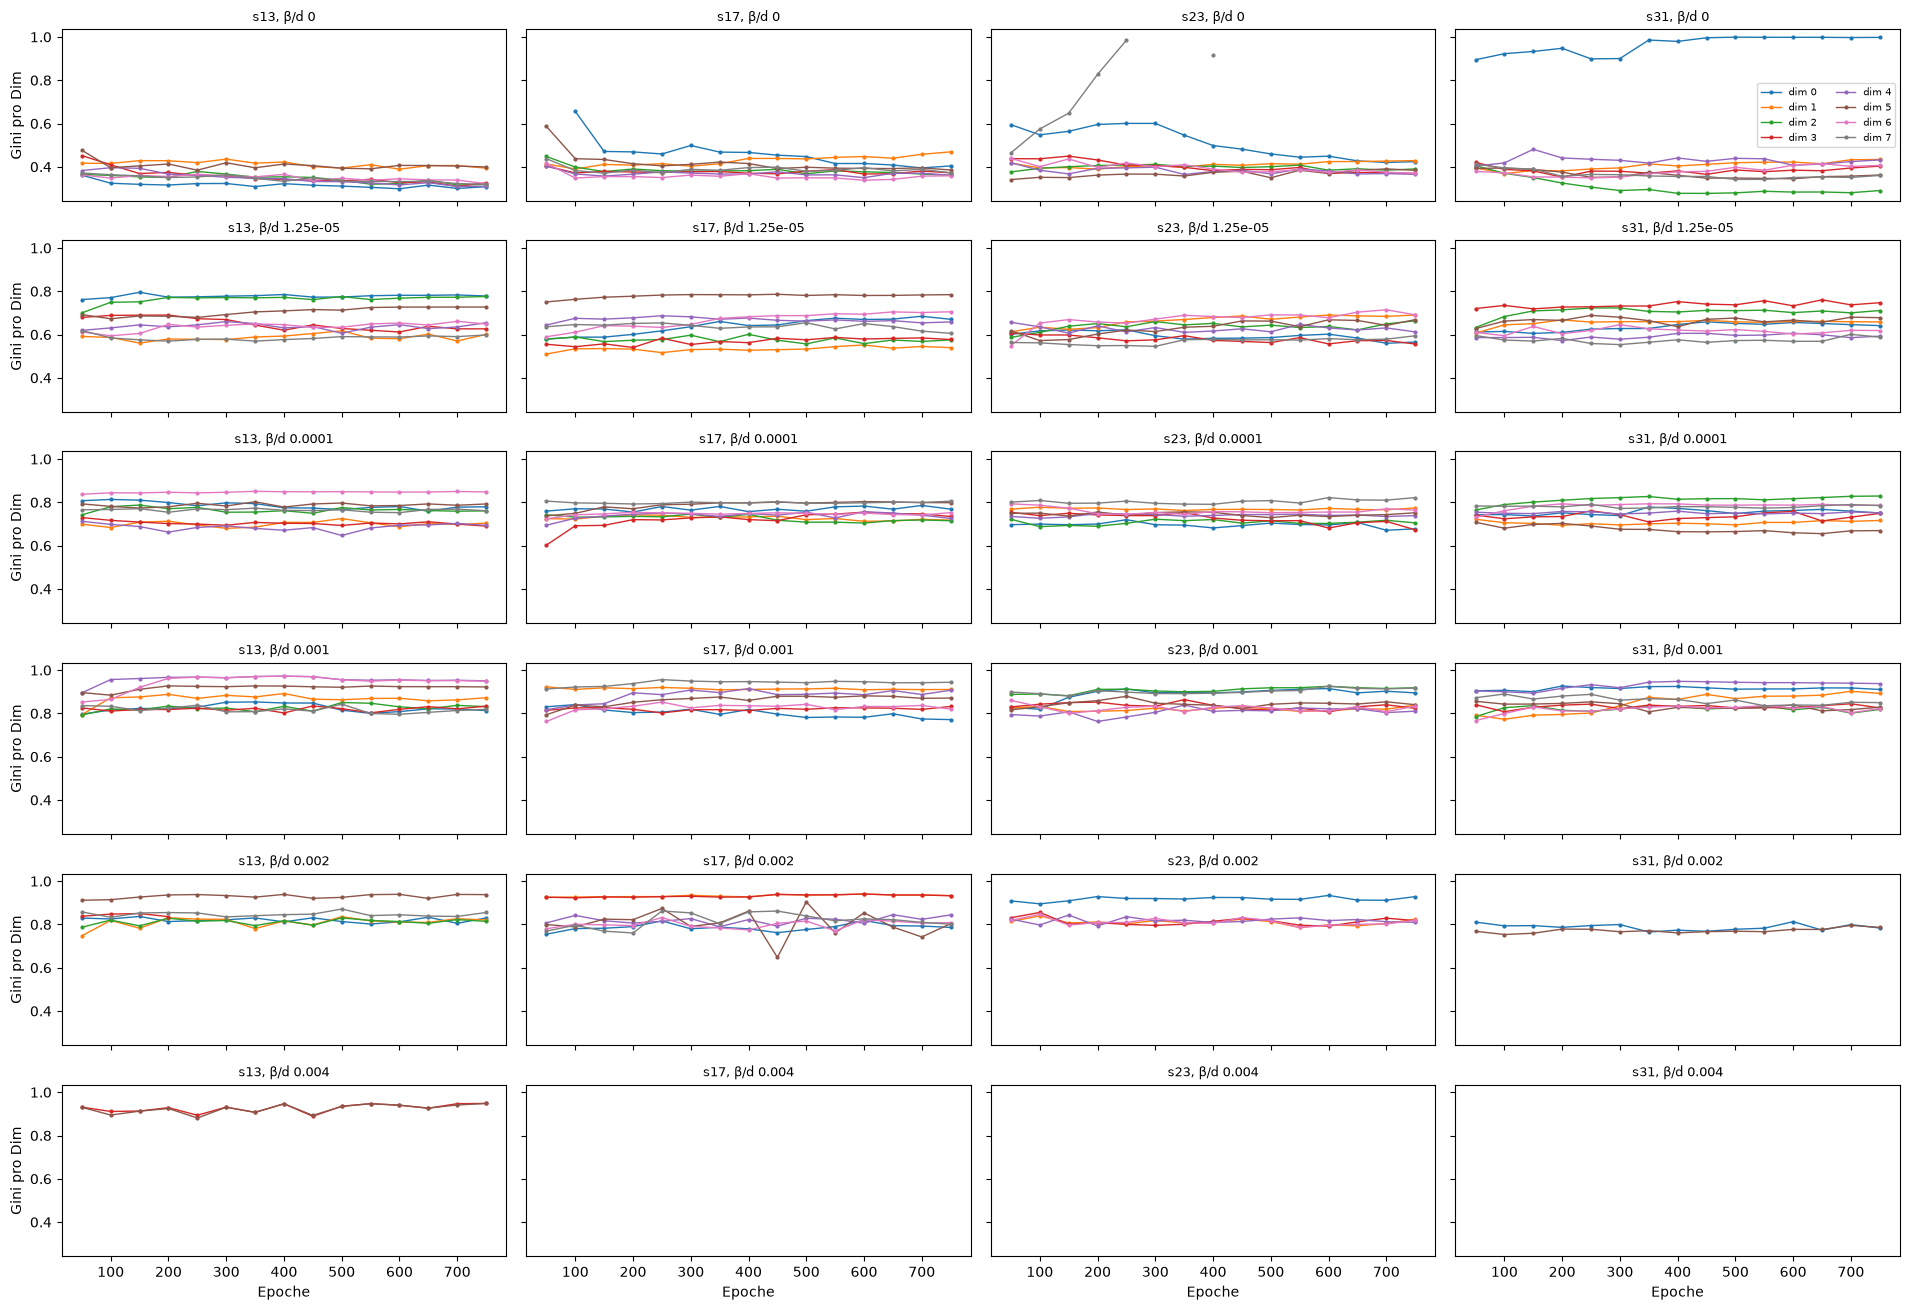

In [6]:
SHOWN_BETAS = tuple(b for b in (0.0, 1.25e-5, 1e-4, 1e-3, 2e-3, 4e-3) if b in TCGA_BETAS)
fig, axes = plt.subplots(len(SHOWN_BETAS), len(TCGA_SEEDS), figsize=(4.8 * len(TCGA_SEEDS), 2.2 * len(SHOWN_BETAS)),
                         sharex=True, sharey=True)
tcga_dims = dims[dims.dataset.eq("tcga")]
for row, beta in enumerate(SHOWN_BETAS):
    for column, seed in enumerate(TCGA_SEEDS):
        ax = axes[row, column]
        part = tcga_dims[tcga_dims.seed.eq(seed) & np.isclose(tcga_dims.beta_over_d, beta)]
        for dim, line in part.groupby("dim"):
            line = line.sort_values("epoch")
            ax.plot(line.epoch, line.gini, "o-", ms=2, color=plt.cm.tab10(dim), lw=1, label=f"dim {dim}")
        ax.set_title(f"s{seed}, β/d {beta:.3g}", fontsize=9)
    axes[row, 0].set_ylabel("Gini pro Dim")
for ax in axes[-1]:
    ax.set_xlabel("Epoche")
axes[0, -1].legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(OUTPUT / "gini_per_dimension.png", dpi=160)
plt.show()

## 6. μ-Matrix in Epoche 750

Zeilen = 1.001 Validierungspatienten, Spalten = 8 Dimensionen, weiß = μ = 0. Farbe pro Feld auf das 99-%-Quantil der
μ ≠ 0 normiert (Wert im Titel). Sortierung nach Krebsart (dünne Linien) und Zahl aktiver Dimensionen, nur für die
Darstellung (Bewertung mit Labels).

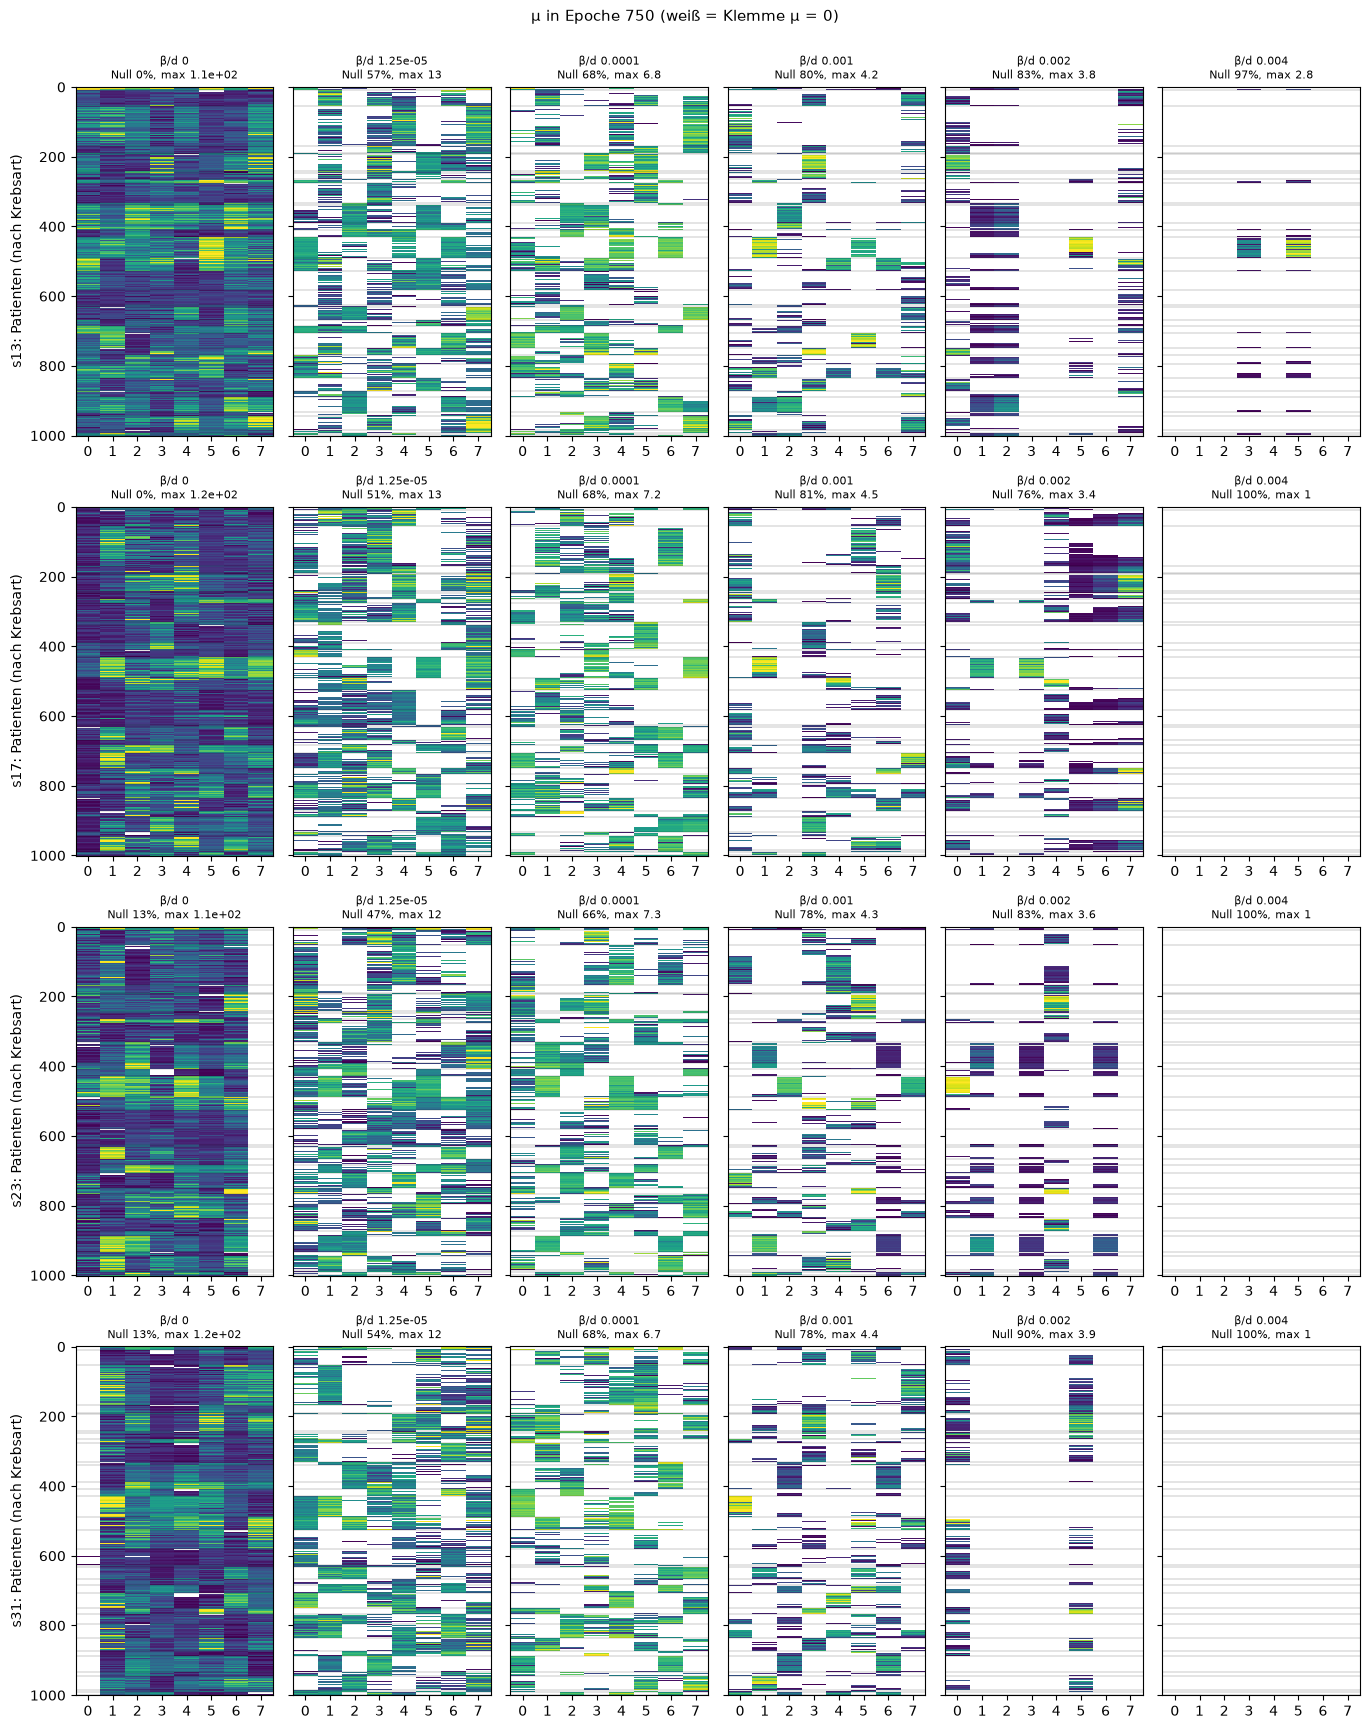

In [7]:
cmap = plt.cm.viridis.copy()
cmap.set_bad("white")
fig, axes = plt.subplots(len(TCGA_SEEDS), len(SHOWN_BETAS), figsize=(2.3 * len(SHOWN_BETAS), 4.4 * len(TCGA_SEEDS)), sharey=True)
for row, seed in enumerate(TCGA_SEEDS):
    for column, beta in enumerate(SHOWN_BETAS):
        ax = axes[row, column]
        run = runs[runs.dataset.eq("tcga") & runs.seed.eq(seed) & np.isclose(runs.beta_over_d, beta)].iloc[0]
        valid = load_split(run.folder, EPOCHS, "valid")
        mu = valid["mu"].astype(np.float64)
        labels = pd.read_parquet(run.folder / "epoch_snapshots" / "labels_valid.parquet")
        labels.index = labels.index.astype(str)
        cancer = labels.loc[valid["sample_ids"].astype(str), "CANCER_TYPE_ACRONYM"].astype(str).to_numpy()
        order = np.lexsort(((mu > 0).sum(1), cancer))
        scale = np.quantile(mu[mu > 0], .99) if (mu > 0).any() else 1.0
        ax.imshow(np.ma.masked_equal(mu[order], 0) / scale, aspect="auto", cmap=cmap, vmin=0, vmax=1, interpolation="nearest")
        ax.hlines(np.flatnonzero(cancer[order][1:] != cancer[order][:-1]) + .5, -.5, mu.shape[1] - .5, color="k", lw=.3, alpha=.5)
        ax.set_xticks(range(mu.shape[1]))
        ax.set_title(f"β/d {beta:.3g}\nNull {np.mean(mu == 0):.0%}, max {scale:.2g}", fontsize=8)
    axes[row, 0].set_ylabel(f"s{seed}: Patienten (nach Krebsart)")
fig.suptitle("μ in Epoche 750 (weiß = Klemme μ = 0)", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, .98))
fig.savefig(OUTPUT / "gini_heatmaps.png", dpi=160)
plt.show()

## 7. Negativkontrollen: Circle und Swiss Roll (d = 2)

Gleiche Kennzahlen in Epoche 750. Bei d = 2 ist der Gini pro Patient grob (nur zwei Werte, höchstens ½); aussagekräftig
sind Null-Anteil, Gini pro Dimension und tote Dimensionen.

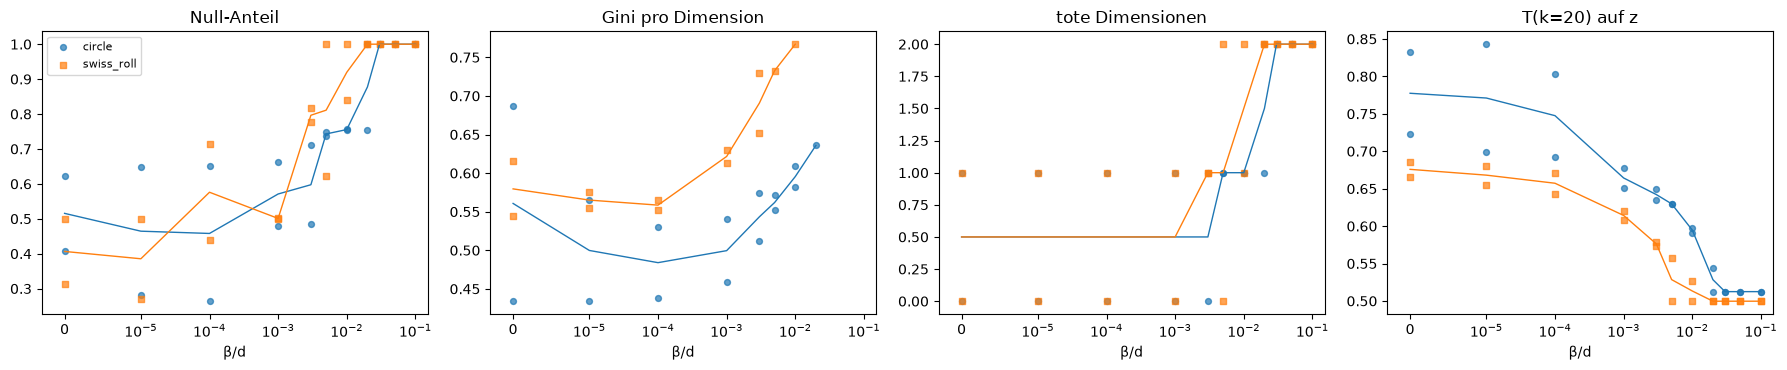

dead_dims            gini_dim_median            zero_share  \
dataset        circle swiss_roll          circle swiss_roll     circle   
beta_over_d                                                              
0.00000           0.5        0.5           0.561      0.580      0.516   
0.00001           0.5        0.5           0.500      0.565      0.464   
0.00010           0.5        0.5           0.484      0.559      0.458   
0.00100           0.5        0.5           0.500      0.622      0.571   
0.00300           0.5        1.0           0.543      0.691      0.597   
0.00500           1.0        1.0           0.562      0.733      0.743   
0.01000           1.0        1.5           0.596      0.767      0.756   
0.02000           1.5        2.0           0.636        NaN      0.878   
0.03000           2.0        2.0             NaN        NaN      1.000   
0.05000           2.0        2.0             NaN        NaN      1.000   
0.10000           2.0        2.0             NaN        NaN      1.000   

                        
dataset     swiss_roll  
beta_over_d             
0.00000          0.406  
0.00001          0.386  
0.00010          0.576  
0.00100          0.501  
0.00300          0.796  
0.00500          0.811  
0.01000          0.920  
0.02000          1.000  
0.03000          1.000  
0.05000          1.000  
0.10000          1.000

In [8]:
controls = summary[summary.dataset.isin(["circle", "swiss_roll"]) & summary.epoch.eq(EPOCHS)]
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, (key, label) in zip(axes, [("zero_share", "Null-Anteil"), ("gini_dim_median", "Gini pro Dimension"),
                                   ("dead_dims", "tote Dimensionen"), ("trustworthiness_z", "T(k=20) auf z")]):
    for dataset, marker in (("circle", "o"), ("swiss_roll", "s")):
        part = controls[controls.dataset.eq(dataset)]
        ax.scatter(part.beta_over_d, part[key], marker=marker, s=18, alpha=.7, label=dataset)
        median = part.groupby("beta_over_d")[key].median()
        ax.plot(median.index, median.values, lw=1)
    ax.set_xscale("symlog", linthresh=1e-5)
    ax.set_xlim(-3e-6, 0.15)
    ax.set(title=label, xlabel="β/d")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "gini_controls.png", dpi=160)
plt.show()
display(controls.pivot_table(index="beta_over_d", columns="dataset", values=["zero_share", "gini_dim_median", "dead_dims"],
                             aggfunc="median").round(3))

## 8. Tabelle Epoche 750 und Vergleich mit der Leiter

Median über die 4 Seeds; in Klammern Minimum bis Maximum. Rechts das Stufenende derselben β/d auf der Leiter
(`sparsity_ladder`, 800-Patienten-Subset; bei β = 0 Ende des Warm-ups nach 300 Epochen).

In [9]:
columns = ["rate", "dead_dims", "zero_share", "gini_pooled", "gini_dim_median", "gini_patient_median", "active_dims_per_patient",
           "patients_all_zero", "patterns", "d_eff", "trustworthiness_z", "auc_cancer", "auc_sex_mixed"]
grouped = final.groupby("beta_over_d")[columns]
table = (grouped.median().round(3).astype(str) + " (" + grouped.min().round(2).astype(str) + "–"
         + grouped.max().round(2).astype(str) + ")")
if LADDER_SPARSITY.exists():
    ladder = pd.read_csv(LADDER_SPARSITY).rename(columns={"β/d": "beta_over_d"})
    ladder = ladder.groupby("beta_over_d")[["Null-Anteil", "Gini/Patient (Median)", "tote Dims"]].median().add_prefix("Leiter ")
    table = table.join(ladder.round(3), how="left")
table.to_csv(OUTPUT / "gini_final.csv")
display(table)

,rate,dead_dims,zero_share,gini_pooled,gini_dim_median,gini_patient_median,active_dims_per_patient,patients_all_zero,patterns,d_eff,trustworthiness_z,auc_cancer,auc_sex_mixed,Leiter Null-Anteil,Leiter Gini/Patient (Median),Leiter tote Dims
beta_over_d,,,,,,,,,,,,,,,,
0.000000,8558.313 (8211.07–12427.15),0.5 (0.0–1.0),0.069 (0.0–0.13),0.44 (0.34–0.48),0.378 (0.32–0.4),0.344 (0.24–0.38),7.445 (6.92–7.96),0.0 (0.0–0.0),10.0 (9.0–14.0),6.58 (4.04–7.86),0.945 (0.94–0.96),0.992 (0.99–0.99),0.963 (0.86–1.0),0.120,0.363,0.0
0.000001,340.163 (328.86–348.59),0.0 (0.0–0.0),0.174 (0.13–0.19),0.507 (0.48–0.55),0.488 (0.48–0.52),0.455 (0.43–0.5),6.61 (6.46–6.99),0.0 (0.0–0.0),56.0 (54.0–58.0),7.636 (7.11–7.77),0.962 (0.96–0.96),0.991 (0.99–0.99),0.986 (0.92–0.99),NaN,NaN,NaN
0.000003,190.712 (184.96–191.74),0.0 (0.0–0.0),0.293 (0.27–0.32),0.556 (0.55–0.57),0.554 (0.54–0.56),0.502 (0.5–0.52),5.658 (5.42–5.81),0.0 (0.0–0.0),108.5 (98.0–121.0),7.726 (7.66–7.76),0.963 (0.96–0.96),0.99 (0.99–0.99),0.977 (0.95–0.99),NaN,NaN,NaN
0.000005,123.702 (121.13–131.07),0.0 (0.0–0.0),0.407 (0.38–0.42),0.613 (0.6–0.62),0.616 (0.59–0.62),0.567 (0.55–0.58),4.74 (4.62–4.93),0.0 (0.0–0.0),143.0 (137.0–162.0),7.702 (7.59–7.86),0.959 (0.95–0.96),0.988 (0.99–0.99),0.976 (0.91–0.99),NaN,NaN,NaN
0.000013,72.557 (69.15–73.93),0.0 (0.0–0.0),0.524 (0.47–0.57),0.65 (0.63–0.68),0.644 (0.63–0.65),0.627 (0.6–0.65),3.812 (3.48–4.24),0.0 (0.0–0.0),165.0 (142.0–177.0),7.683 (7.5–7.85),0.942 (0.94–0.95),0.985 (0.98–0.99),0.927 (0.88–0.96),0.323,0.548,0.0
0.000025,48.355 (46.87–50.01),0.0 (0.0–0.0),0.581 (0.54–0.59),0.68 (0.67–0.69),0.675 (0.65–0.68),0.647 (0.64–0.66),3.351 (3.3–3.67),0.0 (0.0–0.0),161.5 (143.0–165.0),7.82 (7.75–7.85),0.928 (0.92–0.93),0.981 (0.98–0.98),0.957 (0.92–0.98),NaN,NaN,NaN
0.000050,31.678 (30.91–34.8),0.0 (0.0–0.0),0.634 (0.61–0.66),0.725 (0.7–0.73),0.718 (0.69–0.74),0.69 (0.66–0.7),2.926 (2.76–3.14),0.003 (0.0–0.01),135.5 (127.0–158.0),7.827 (7.61–7.87),0.908 (0.9–0.91),0.974 (0.97–0.98),0.869 (0.8–0.92),0.489,0.642,0.0
0.000100,21.433 (20.62–22.14),0.0 (0.0–0.0),0.68 (0.66–0.68),0.756 (0.74–0.76),0.748 (0.74–0.76),0.75 (0.71–0.75),2.559 (2.53–2.7),0.007 (0.0–0.01),100.0 (93.0–121.0),7.781 (7.72–7.89),0.884 (0.88–0.9),0.967 (0.96–0.97),0.717 (0.58–0.76),0.583,0.692,0.0
0.000250,12.038 (11.41–12.46),0.0 (0.0–0.0),0.726 (0.71–0.75),0.794 (0.78–0.81),0.799 (0.78–0.81),0.761 (0.76–0.77),2.192 (2.02–2.33),0.025 (0.01–0.06),73.0 (69.0–91.0),7.804 (7.7–7.93),0.834 (0.83–0.84),0.936 (0.92–0.95),0.589 (0.57–0.65),0.670,0.754,0.0


## 9. Rate und Gini in einem Bild

Zusammenhang (hergeleitet, siehe oben): R_j ≈ ½ · (1 − p₀) · E[μ_j² | μ_j > 0]. Der Gini ist skaleninvariant und sieht
nur den ersten Faktor (Nullen) plus die Ungleichheit unter den Aktiven; die Rate sieht zusätzlich das Schrumpfen.

1. **Links:** Gini der ganzen μ-Matrix gegen die Gesamtrate in Epoche 750, ein Punkt pro Lauf (Farbe = β/d, Form = Seed),
   schwarze Linie = Median je β-Stufe.
2. **Mitte:** dieselben Achsen über das Training: jede Linie ein Lauf von Epoche 50 (kleiner Punkt) bis 750 (großer
   Punkt). Zeigt, ob sich ein Lauf entlang der Kurve bewegt oder nur in einer Richtung.
3. **Rechts:** pro Dimension: Gini über Patienten gegen R_j (Epoche 750, lebende Dimensionen).

Läufe mit Rate ≈ 0 (alle μ = 0) haben keinen Gini und fehlen; die Rate-Achse ist logarithmisch.

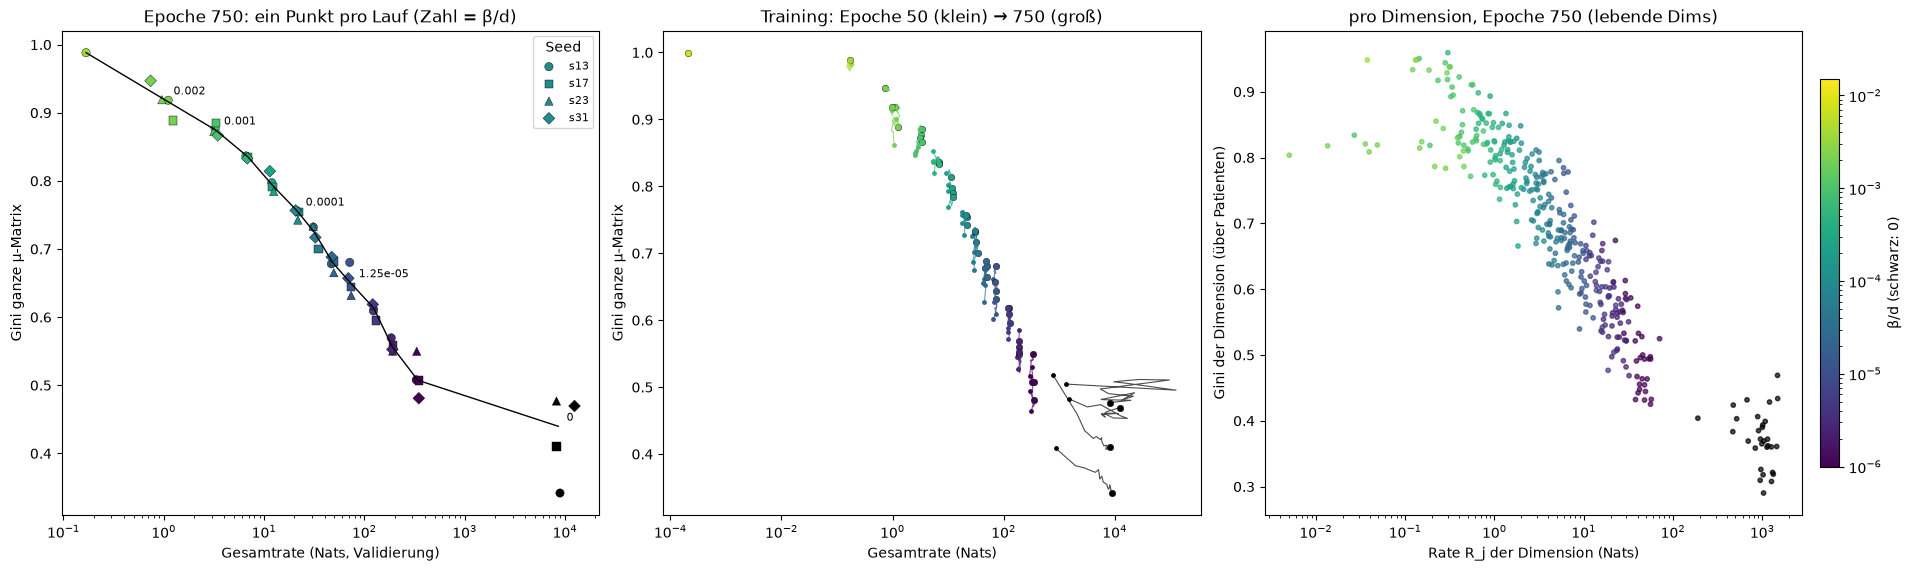

In [10]:
markers = dict(zip(TCGA_SEEDS, ("o", "s", "^", "D")))
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), layout="constrained")
ax = axes[0]
shown = final.dropna(subset=["gini_pooled"])
for seed, part in shown.groupby("seed"):
    ax.scatter(part.rate, part.gini_pooled, c=[beta_color(b) for b in part.beta_over_d], marker=markers[seed], s=36,
               edgecolor="k", linewidth=.3, label=f"s{seed}")
median = shown.groupby("beta_over_d")[["rate", "gini_pooled"]].median()
ax.plot(median.rate, median.gini_pooled, color="k", lw=1)
for beta, row in median.iterrows():
    if beta in (0.0, 1.25e-5, 1e-4, 1e-3, 2e-3):
        ax.annotate(f"{beta:.3g}", (row.rate, row.gini_pooled), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set(xscale="log", xlabel="Gesamtrate (Nats, Validierung)", ylabel="Gini ganze μ-Matrix",
       title="Epoche 750: ein Punkt pro Lauf (Zahl = β/d)")
ax.legend(fontsize=8, title="Seed")

ax = axes[1]
for tag, part in tcga.dropna(subset=["gini_pooled"]).groupby("tag"):
    part = part.sort_values("epoch")
    color = beta_color(part.beta_over_d.iloc[0])
    ax.plot(part.rate, part.gini_pooled, color=color, lw=.8, alpha=.7)
    ax.scatter(part.rate.iloc[0], part.gini_pooled.iloc[0], color=color, s=6)
    ax.scatter(part.rate.iloc[-1], part.gini_pooled.iloc[-1], color=color, s=22, edgecolor="k", linewidth=.3)
ax.set(xscale="log", xlabel="Gesamtrate (Nats)", ylabel="Gini ganze μ-Matrix",
       title="Training: Epoche 50 (klein) → 750 (groß)")

ax = axes[2]
dim_final = tcga_dims[tcga_dims.epoch.eq(EPOCHS) & tcga_dims.zero_share.lt(DEAD)]
ax.scatter(dim_final.rate, dim_final.gini, c=[beta_color(b) for b in dim_final.beta_over_d], s=10, alpha=.7)
ax.set(xscale="log", xlabel="Rate R_j der Dimension (Nats)", ylabel="Gini der Dimension (über Patienten)",
       title="pro Dimension, Epoche 750 (lebende Dims)")
colorbar = fig.colorbar(plt.cm.ScalarMappable(norm=BETA_NORM, cmap="viridis"), ax=axes, shrink=.8, pad=.01)
colorbar.set_label("β/d (schwarz: 0)")
fig.savefig(OUTPUT / "gini_rate.png", dpi=160)
plt.show()

## 10. Befunde (gemessen, 60 TCGA-Läufe + 44 Kontrollläufe, Epoche 750 wenn nicht anders angegeben)

1. **Sparsity steigt monoton mit β, sehr reproduzierbar.** Null-Anteil (Median über 4 Seeds): 7 % bei β = 0, 17 % bei
   10⁻⁶, 52 % bei 1,25·10⁻⁵, 68 % bei 10⁻⁴, 79 % bei 10⁻³, 83 % bei 2·10⁻³, 100 % ab 4·10⁻³. Spannweite über die Seeds
   meist ≤ 0,1. Gini pro Patient von 0,34 auf 0,875 = 7/8 bei 2·10⁻³: der Median-Patient hat dann nur noch **eine**
   aktive Dimension. Gini der ganzen μ-Matrix: 0,44 bei β = 0, 0,76 bei 10⁻⁴, 0,88 bei 10⁻³, 0,92 bei 2·10⁻³, 0,99 bei
   4·10⁻³; als einziges Gini-Maß streng monoton im Median (Spearman über alle Läufe 0,996). Der Median über die lebenden
   Dimensionen knickt bei 2·10⁻³ ein (0,85 → 0,81), weil dort die dünnsten Dimensionen sterben (Überlebenden-Effekt).
2. **Sparsity und Krebsart-AUC hängen eng zusammen** (Spearman −0,98 über die Läufe bis 2·10⁻³), aber nicht linear: die
   AUC bleibt ≥ 0,97 bis Gini pro Patient ≈ 0,70 (β/d ≤ 5·10⁻⁵) und fällt erst danach steil (Abschnitt 4, unten rechts).
   Die Geschlechts-AUC fällt viel früher (Median 0,93–0,99 bis 2,5·10⁻⁵, 0,72 bei 10⁻⁴), wie auf der Leiter.
3. **D_eff bleibt flach** (7,5–7,8 von 10⁻⁶ bis 5·10⁻⁴) und fällt erst an der Kante (3,4 bei 2·10⁻³): die Rate bleibt
   gleichmäßig über die Dimensionen verteilt, obwohl jeder Patient immer weniger Dimensionen nutzt. Der Code wird also
   **pro Patient** dünn, nicht pro Dimension.
4. **Bei festem β liegt die Kante früher als auf der Leiter.** Bei β/d = 2·10⁻³ sind 1–6 Dimensionen tot (Median 3),
   bei 4·10⁻³ 6–8; auf der Leiter war 2·10⁻³ die letzte Stufe ohne Collapse. Die toten Dimensionen sind schon im ersten
   Snapshot (Epoche 50) tot. Kante bei festem β also zwischen 10⁻³ und 2·10⁻³ (gemessen); dass das stufenweise Hochfahren
   den Collapse hinausschiebt, ist eine **Hypothese** (gleiche Daten und Architektur, aber Leiter = 1 Lauf je Seed mit
   anderer Vorgeschichte).
5. **Sparsity schwingt bei kleinem β langsamer ein als der Verlust.** Bei β/d 10⁻⁶ bis 10⁻⁴ steigt der Null-Anteil
   zwischen Epoche 100 und 750 noch deutlich (z. B. 1,25·10⁻⁵: 0,37 → 0,52; 10⁻⁴: 0,59 → 0,68), obwohl sich die
   Rekonstruktion zwischen 650 und 750 um ≤ 1 % ändert. Ab 5·10⁻⁴ ist die Sparsity nach 100 Epochen fast fertig.
   Gegenüber der Leiter (100 Epochen pro Stufe) ist der feste Lauf bei kleinem β deshalb dünner besetzt
   (1,25·10⁻⁵: 0,52 gegen 0,32); ab 10⁻³ stimmen beide überein (0,79).
6. **Tote Dimensionen bei kleinem β sind Klemm-Artefakte**, kein β-Collapse: s17 hat bei β = 0, 2,5·10⁻⁶, 5·10⁻⁶,
   5·10⁻⁴ und 10⁻³ je eine Dimension, die schon in Epoche 50 tot ist; bei β = 0 sterben in s23 und s31 je eine Dimension
   spät (Epoche 300 bzw. 500). Das passt zu `trustworthiness_annealer` (Klemm-Tod auch bei β = 0).
7. **Negativkontrollen (Circle, Swiss Roll, d = 2):** Null-Anteil schon bei β = 0 bei 41–52 %, und in einem der zwei Seeds
   ist eine Dimension von Anfang an tot. Sparsity entsteht also auch ohne Clusterstruktur; sie beschreibt den
   Klemm-Mechanismus von Varix, nicht die Struktur der Daten. Null-Anteil und Gini sind deshalb **kein Clustermaß**.
8. **Als Steuersignal:** Null-Anteil und Gini pro Patient sind monoton, über Seeds ruhig und billig (nur μ), messen aber
   den Kompressionsgrad, nicht den Abstand zur Kante: zwischen 10⁻³ und 2·10⁻³ steigt der Null-Anteil nur von 0,79 auf
   0,83, während 3 Dimensionen sterben. Für die Collapse-Grenze bleibt die Rate pro Dimension das Kriterium.
9. **Gini und Rate liegen auf einer Kurve** (Abschnitt 9). Für 0 < β/d ≤ 2·10⁻³ gilt in Epoche 750 empirisch
   Gini ≈ 0,96 − 0,17 · log₁₀(Rate) (R² = 0,97, Residuen-SD 0,022, 44 Läufe); mit allen Snapshots von Epoche 50 bis 750
   praktisch dieselbe Gerade (0,96 − 0,17 · log₁₀, R² = 0,97, 660 Punkte). Die Läufe bewegen sich während des Trainings
   *entlang* dieser Kurve: wer Rate abgibt, wird um denselben Betrag dünner. Pro Zehnerpotenz weniger Rate steigt der
   Gini um etwa 0,17. **β = 0 liegt daneben** (Gini 0,04–0,20 über der Geraden bei Rate 8.000–12.000 Nats, Pfade
   unruhig): ohne KL-Druck bestimmt nicht die Rate, sondern der Klemm-Tod einzelner Dimensionen die Sparsity. Die
   Gerade ist eine empirische Beschreibung, keine hergeleitete Beziehung; hergeleitet ist nur, dass der Gini den
   Null-Anteil-Faktor der Rate sieht und den Schrumpf-Faktor nicht.